## Customer Segmentation System

#### Business problem: 
A company has thousands of customers with different purchasing habits. It wants to understand its customer base and develop targeted marketing strategies.

#### Project objective: 
Identify meaningful customer segments using unsupervised learning.

#### Key questions to investigate:
1. Are there identifiable groups of high-spending customers?
2. Which customers are particularly sensitive to discounts?
3. Which customers purchase frequently?
4. Which customers might be at risk of becoming inactive?
5. How do digital engagement and loyalty differ across customer groups?
6. Can customer segmentation help the business develop more targeted marketing campaigns?

In [34]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import joblib

### Data Loading and Understanding

In [3]:
# Load the data
df = pd.read_csv('customer_segmentation.csv')
df.head()

,customer_id,age,annual_income_usd,region,customer_tenure_months,orders_last_12m,avg_order_value_usd,total_spend_last_12m_usd,days_since_last_purchase,discount_order_share,...,web_session_share,app_session_share,email_open_rate,support_tickets_last_12m,satisfaction_score_1_5,loyalty_points_thousands,preferred_category,preferred_channel,preferred_shipping,marketing_opt_in
0,C113906,48.9,NaN,East,5.3,1,40.04,34.56,31.6,0.458,...,0.297,0.167,0.391,1,3.81,2.28,NaN,Market Place,Pickup,Yes
1,C105664,51.2,85581.53,East,23.4,8,129.4,855.36,0.3,0.661,...,0.782,0.272,0.715,2,3.91,5.03,Beauty,Market Place,Pickup,Yes
2,C105107,36.7,107379.49,West,77.5,14,219.87,3285.46,42.4,0.829,...,0.591,0.494,0.623,1,4.41,10.00,Electronics,Mobile App,Standard,No
3,C117240,44.9,30854.82,Central,28.6,8,90.94,706.6,38.2,0.431,...,0.372,0.707,0.558,1,4.44,5.79,Electronics,Store,Standard,No
4,C113089,48.5,57984.88,North,5.5,1,66.65,52.35,26.7,0.075,...,0.285,0.403,0.160,2,3.87,1.49,Electronics,Web,Express,No


In [4]:
# Check the shape of dataset
df.shape

(20100, 21)

In [5]:
# Describe the data
df.describe()

,age,customer_tenure_months,orders_last_12m,days_since_last_purchase,discount_order_share,return_rate,web_session_share,app_session_share,email_open_rate,support_tickets_last_12m,satisfaction_score_1_5,loyalty_points_thousands
count,19343.000000,19592.000000,20100.000000,19583.000000,20100.000000,20100.000000,20100.000000,20100.000000,20100.000000,20100.000000,18709.000000,20100.000000
mean,38.510262,34.943518,6.255373,33.712005,0.482984,0.079910,0.558053,0.408114,0.421616,1.254080,3.825038,3.778179
std,13.010233,31.160673,3.879768,61.634090,0.280736,0.074876,0.230916,0.264264,0.238072,1.408704,0.884759,2.547090
min,-4.000000,0.100000,1.000000,-10.000000,0.000000,0.000000,0.015000,0.001000,0.001000,0.000000,0.000000,0.000000
25%,28.700000,12.500000,3.000000,5.800000,0.254000,0.027000,0.373000,0.194000,0.214000,0.000000,3.240000,1.760000
50%,38.200000,25.500000,6.000000,14.600000,0.458000,0.058000,0.552000,0.345000,0.421000,1.000000,3.920000,3.590000
75%,47.600000,47.600000,9.000000,33.500000,0.715250,0.108000,0.751000,0.595250,0.614250,2.000000,4.530000,5.560000
max,150.000000,180.000000,22.000000,1200.000000,1.000000,0.744000,0.998000,0.997000,0.987000,10.000000,9.000000,10.000000


### Data Cleaning

In [6]:
# Check for duplicate records
dup = df.duplicated().sum()
print("No. of duplicate records:", dup)
if dup>0:
    df.drop_duplicates(inplace=True)
    dup_new = df.duplicated().sum()
    print("Duplicate records after cleaning:", dup_new)

No. of duplicate records: 100
Duplicate records after cleaning: 0


In [7]:
# Check for special characters in every column
pattern = r'[^a-zA-Z0-9.\s]'
special_char_check = df.apply(lambda x: x.astype(str).str.contains(pattern, regex=True, na=False))

# Get only columns containing special characters
special_cols = special_char_check.any()
for col in special_cols[special_cols].index:
    mask = special_char_check[col]
    print(col, ':', df.loc[mask, col].unique(), '\n')

age : [-4.] 

annual_income_usd : <ArrowStringArray>
['$128,063.82', '$272,207.07',  '$15,588.77',  '$44,952.94', '$114,734.57',
  '$33,559.08',  '$61,261.58',  '$26,733.38',  '$30,613.78',  '$39,132.97',
 ...
  '$32,962.46',  '$41,327.81',  '$90,523.96', '$109,334.10',  '$38,182.32',
  '$56,215.79',  '$32,804.73',  '$55,825.73',  '$63,566.72',  '$94,493.99']
Length: 169, dtype: str 

avg_order_value_usd : <ArrowStringArray>
['$300.97',  '$66.85',  '$38.99',  '$63.30', '$108.40',  '$39.22', '$300.09',
  '$91.90', '$170.51',  '$71.89',
 ...
  '$81.32',  '$55.60',  '$71.91',  '$66.46', '$173.27', '$173.47', '$121.08',
 '$152.66', '$127.46', '$135.01']
Length: 173, dtype: str 

total_spend_last_12m_usd : <ArrowStringArray>
['$1,693.45', '$1,294.60', '$1,869.04',   '$912.33', '$1,625.40',    '$95.66',
   '$105.02',   '$145.37',   '$860.89',   '$214.99',
 ...
   '$466.74',   '$110.77',    '$78.77',   '$126.06',   '$561.57',   '$338.31',
 '$3,664.50',   '$838.28', '$7,126.88',   '$119.44']
L

There are some negative values in the age and days since last purchase column. Also, the amounts are having a dollar ($) symbol and comma (,) along with it. These values needs to be handled in the subsequent steps.

In [8]:
# Replace the negative values of age and days since last purchase with null
df.loc[df['age']<0, 'age'] = np.nan
df.loc[df['days_since_last_purchase']<0, 'days_since_last_purchase'] = np.nan

In [9]:
# Remove the $ symbol from the amount
cols = ['annual_income_usd', 'avg_order_value_usd', 'total_spend_last_12m_usd']
for i in cols:
    df[i] = df[i].str.replace('$', '').str.replace(',', '')

In [10]:
# Check for null values and their percentages
null_count = df.isna().sum()
null_percent = round(null_count*100/len(df), 2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent[df_null_percent['Null Count']>0]

,Null Count,Null Percent
age,763,3.82
annual_income_usd,1230,6.15
customer_tenure_months,505,2.52
avg_order_value_usd,592,2.96
days_since_last_purchase,522,2.61
satisfaction_score_1_5,1385,6.92
preferred_category,488,2.44
preferred_channel,383,1.92
marketing_opt_in,300,1.50


In [11]:
# Replace the missing values in numerical columns by its median
cols = ['age', 'annual_income_usd', 'customer_tenure_months', 'days_since_last_purchase']
for i in cols:
    df[i] = df[i].astype(float)
    df[i] = df[i].fillna(df[i].median())

In [12]:
# Fill the missing values in prefered category and channel, marketing opt in with mode
cols = ['preferred_category', 'preferred_channel', 'marketing_opt_in']
for i in cols:
    df[i] = df[i].fillna(df[i].mode()[0])

In [13]:
# Fill the values in avg order value and satisfaction score as the category median
cols = ['avg_order_value_usd', 'satisfaction_score_1_5']
for i in cols:
    df[i] = df[i].astype(float)
    df[i] = df.groupby('preferred_category')[i].transform(lambda x: x.fillna(x.median()))

In [14]:
# Check for null values after Null Handeling
null_count = df.isna().sum()
null_percent = round(null_count*100/len(df), 2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent[df_null_percent['Null Count']>0]

,Null Count,Null Percent


In [15]:
# Check for data consistency in the categorical features
cols = ['region', 'preferred_category', 'preferred_channel', 'preferred_shipping', 'marketing_opt_in']
for i in cols:
    df[i] = df[i].str.upper().str.strip()
    print(i, ':', df[i].unique(), '\n')

region : <ArrowStringArray>
['EAST', 'WEST', 'CENTRAL', 'NORTH', 'SOUTH']
Length: 5, dtype: str 

preferred_category : <ArrowStringArray>
['HOME', 'BEAUTY', 'ELECTRONICS', 'SPORTS', 'FASHION', 'GROCERY',
 'SPORTSWEAR']
Length: 7, dtype: str 

preferred_channel : <ArrowStringArray>
['MARKET PLACE', 'MOBILE APP', 'STORE', 'WEB', 'MARKETPLACE', 'IN-STORE']
Length: 6, dtype: str 

preferred_shipping : <ArrowStringArray>
['PICKUP', 'STANDARD', 'EXPRESS', 'PICK-UP']
Length: 4, dtype: str 

marketing_opt_in : <ArrowStringArray>
['YES', 'NO', 'N', 'Y']
Length: 4, dtype: str 



In [16]:
# Replace the repeating values for data consistency
df['marketing_opt_in'] = df['marketing_opt_in'].replace({'Y': 'YES', 'N': 'NO'})
df['preferred_shipping'] = df['preferred_shipping'].replace('PICK-UP', 'PICKUP')
df['preferred_channel'] = df['preferred_channel'].replace({'IN-STORE': 'STORE', 'MARKET PLACE': 'MARKETPLACE'})

In [17]:
# Seggregate the numerical and categorical columns
num_cols = ['age', 'annual_income_usd', 'customer_tenure_months', 'avg_order_value_usd',
            'total_spend_last_12m_usd', 'days_since_last_purchase', 'discount_order_share', 'return_rate', 
            'web_session_share', 'app_session_share', 'email_open_rate', 'satisfaction_score_1_5', 
            'loyalty_points_thousands']
discrete_num_cols = ['orders_last_12m', 'support_tickets_last_12m']
cat_cols = ['region', 'preferred_category', 'preferred_channel', 'preferred_shipping', 'marketing_opt_in']

In [18]:
# Check if any non numeric values exist in the numeric columns
for col in num_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    mask = converted.isna() & df[col].notna()
    if mask.any():
        print(col, ':', df.loc[mask, col].unique())
    else:
        df[col] = df[col].astype(float)

In [19]:
# Check if any rate features are outside 0 to 1
rate_cols = ['discount_order_share', 'return_rate', 'web_session_share', 'app_session_share', 'email_open_rate']
for col in rate_cols:
    invalid = ~df[col].between(0, 1)
    print(col, invalid.sum())

discount_order_share 0
return_rate 0
web_session_share 0
app_session_share 0
email_open_rate 0


### Data Visualization

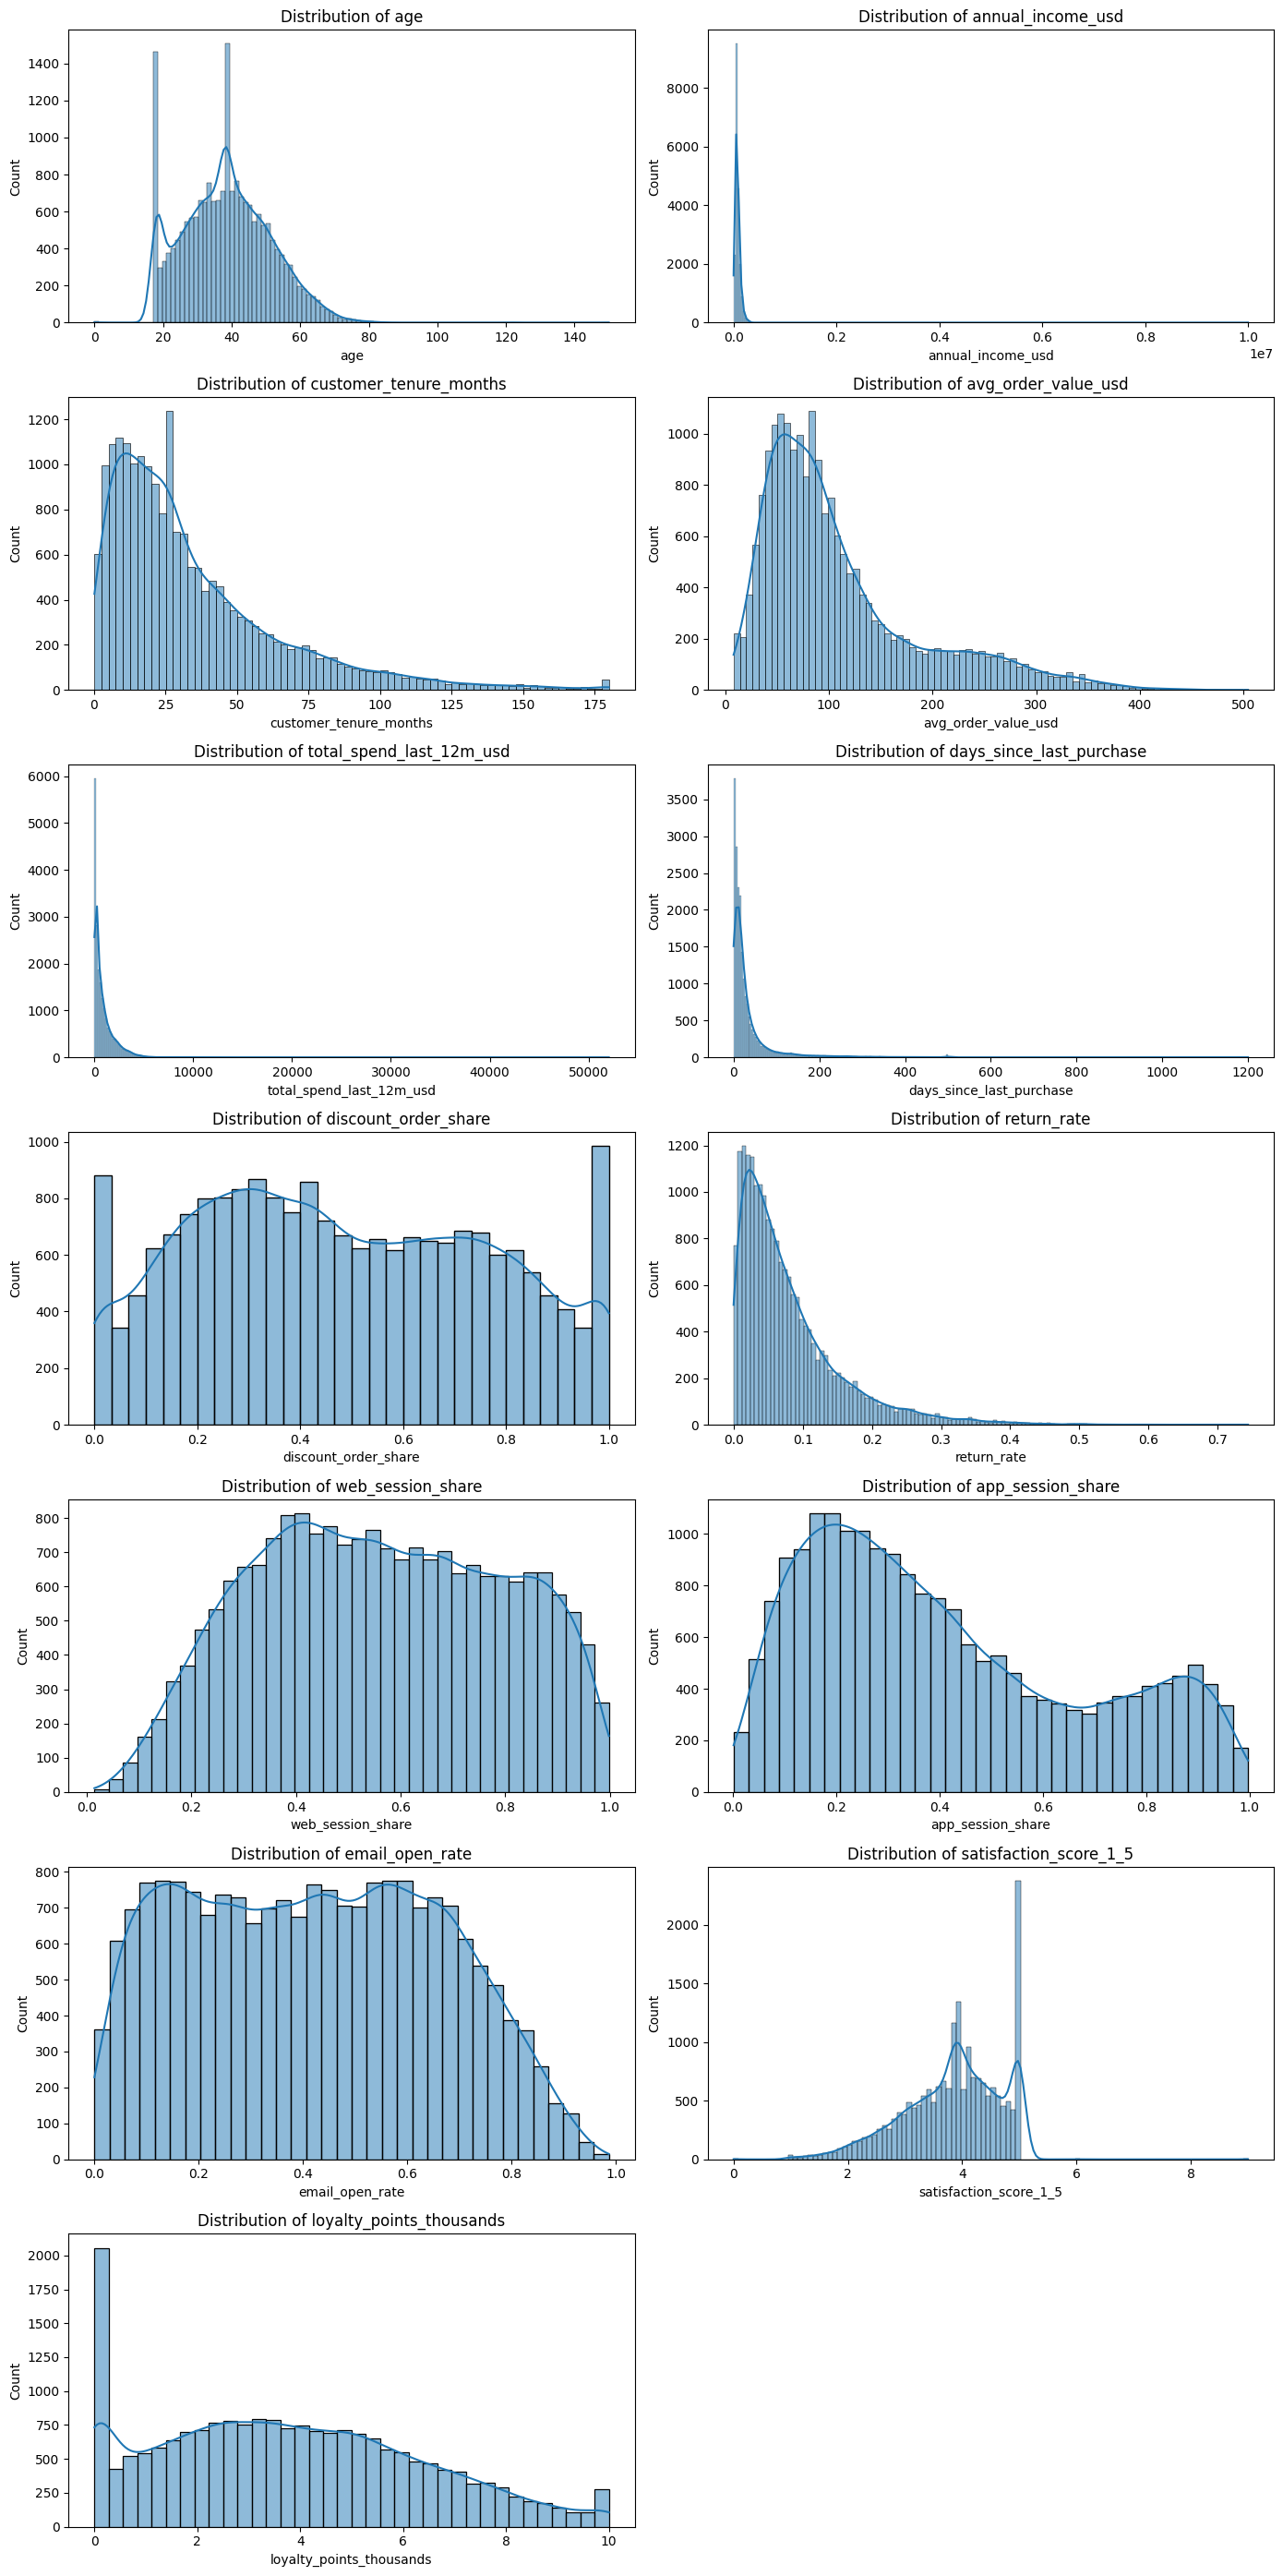

In [19]:
# Univariate Analysis - Check for numerical columns
no_of_rows = int((len(num_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Bsiness Insights:
1. Age - Age is mainly concentrated among adult customers, but the distribution contains suspicious extreme values and pronounced spikes around specific ages. The age range extends from around 0 to ~150, which strongly suggests invalid/outliers that needs further investigation.
2. Annual Income - Annual income is extremely right-skewed, with the majority of customers concentrated at much lower income levels and a few exceptionally large values. The outlier values needs to be investigated.
3. Customer Tenure - Customer tenure is right-skewed, with a larger proportion of relatively newer customers and progressively fewer customers with very long relationships. Tenure is useful for distinguishing newer, developing, established, and long-standing customer relationships.
4. Average Order Value - Average order value is right-skewed, with most customers having lower-to-moderate order values and relatively few customers making very high-value purchases. AOV directly captures purchasing behavior and can separate budget, mainstream, and premium-spending customers.
5. Total Spend in last 12 month - This feature is highly right-skewed, with most customers having relatively low annual spend and a small number showing extremely high spending.
6. Days since last purchase - The distribution is strongly right-skewed, with most customers purchasing recently while a small segment has been inactive for a substantially longer period. This is an useful feature that can distinguish between active customers from dormant/lapsed customers.
7. Discount Share - Discount usage is widely distributed across the 0–1 range, indicating substantial variation in customers' dependence on discounted purchases. This can distinguish full-price customers from promotion-sensitive customers. Some of the discount rate is 1 (ie 100%) that needs further investigation.
8. Return Rate - Return rate is strongly right-skewed, with most customers having low return rates and a smaller group exhibiting substantially higher return behavior. This can distinguish the customers based on their satisfaction of the products.
9. Web Session Share - Web session share spans almost the full 0–1 range, with customer activity concentrated around moderate-to-high web usage. It can distinguish web-oriented customers from other channel behaviors.
10. App Session Share - App session share shows multimodal distribution with substantial customer variation where relatively strong concentrations around lower app usage and another concentration toward high app usage can be seen. However, the relation between web and app session share needs to be investigated.
11. Email Open Rate - Email open rates vary considerably across customers, covering almost the entire 0–1 range with fewer customers at extremely high open rates. It provides an engagement dimension separate from transactional behavior and can help distinguish highly engaged from less responsive customers.
12. Satisfaction Score (1 to 5) - Satisfaction scores are largely concentrated between approximately 3 and 5, with noticeable peaks around scores 4 and 5. Some values are above 5 and needs to be removed.
13. Loyalty Points (in thousands) - Loyalty points are broadly distributed, with a noticeable concentration at or near zero and progressively fewer customers at very high point levels. It can distinguish customers with little/no loyalty activity from more established or highly engaged loyalty customers.

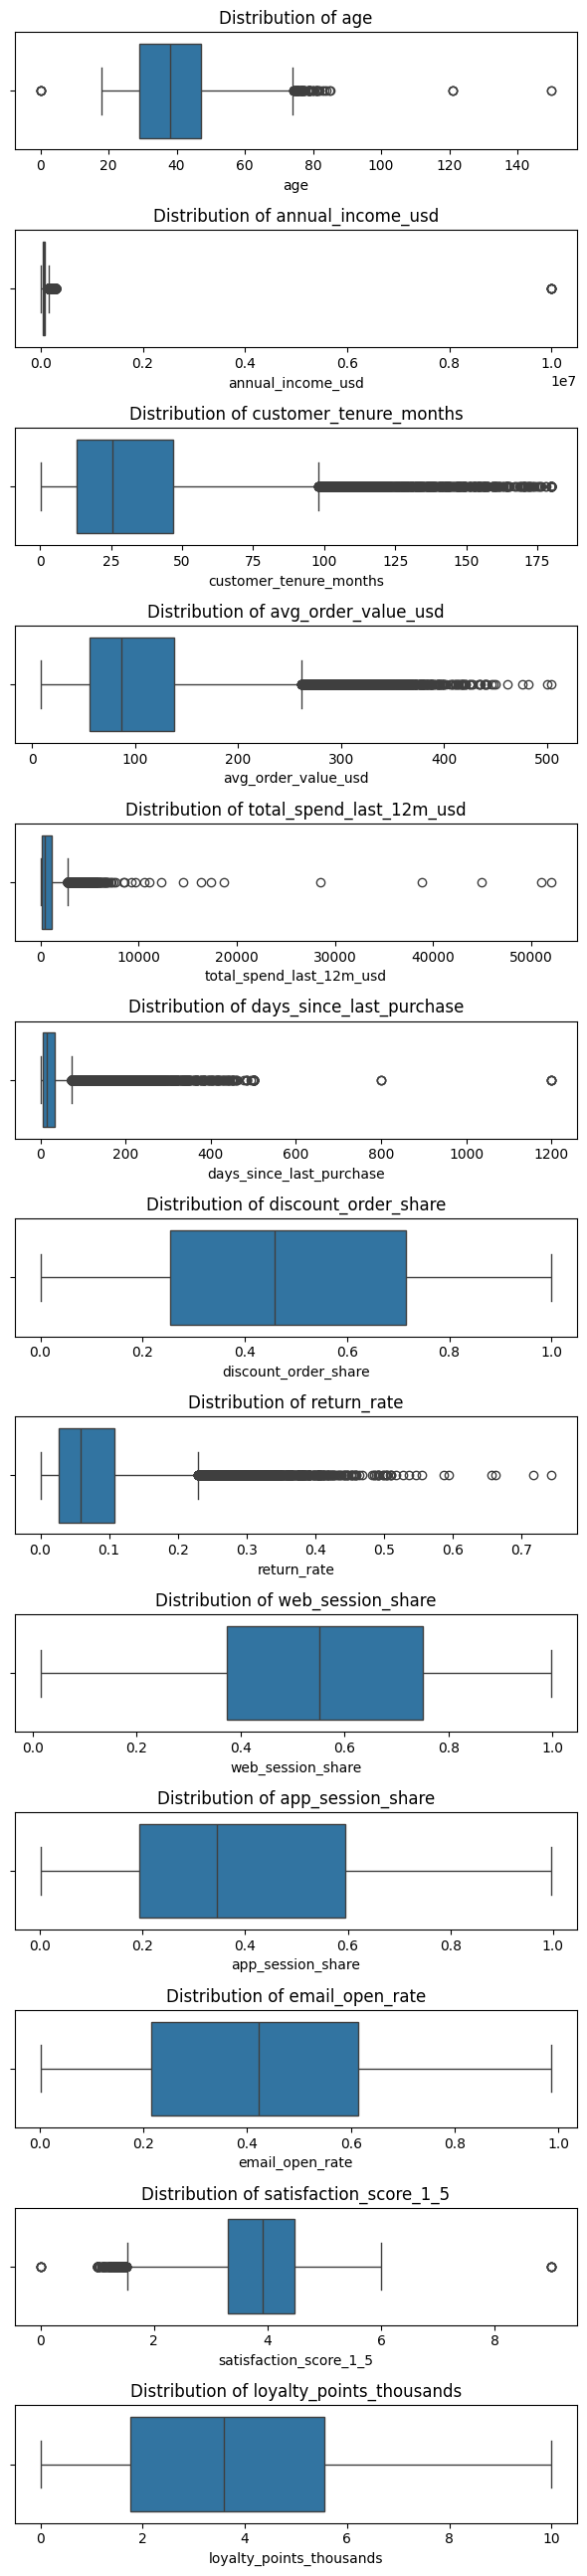

In [20]:
# Check for the outliers in the numerical columns
no_of_rows = len(num_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(6, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [20]:
# Remove the records where age is more than 100, discount is 1 and rating more than 5
df = df[(df['age']<100) & (df['discount_order_share']<1) & (df['satisfaction_score_1_5']<=5) & 
        (df['satisfaction_score_1_5']>=1)]

In [21]:
# Check for the income above $2000000 or negative
df[(df['annual_income_usd']>2000000)|(df['annual_income_usd']<0)]

,customer_id,age,annual_income_usd,region,customer_tenure_months,orders_last_12m,avg_order_value_usd,total_spend_last_12m_usd,days_since_last_purchase,discount_order_share,...,web_session_share,app_session_share,email_open_rate,support_tickets_last_12m,satisfaction_score_1_5,loyalty_points_thousands,preferred_category,preferred_channel,preferred_shipping,marketing_opt_in
1599,C104446,26.8,9999999.0,EAST,10.7,10,114.14,1287.63,5.7,0.743,...,0.888,0.829,0.641,0,3.80,0.12,SPORTS,MOBILE APP,STANDARD,YES
4348,C112744,41.5,9999999.0,SOUTH,69.7,6,146.35,863.88,7.0,0.550,...,0.701,0.445,0.247,1,4.69,7.93,HOME,WEB,EXPRESS,YES
5303,C101742,20.0,-5000.0,SOUTH,56.8,4,143.10,597.34,12.0,0.969,...,0.881,0.726,0.567,1,3.94,5.44,GROCERY,MOBILE APP,EXPRESS,YES
9212,C114065,32.0,9999999.0,WEST,4.4,2,74.52,118.42,3.4,0.164,...,0.341,0.155,0.320,1,3.10,0.00,HOME,STORE,PICKUP,NO
9919,C101303,42.5,-5000.0,EAST,9.1,1,75.03,80.77,3.1,0.340,...,0.091,0.395,0.297,2,2.84,0.00,ELECTRONICS,STORE,STANDARD,NO
15252,C118888,20.8,9999999.0,WEST,1.4,4,45.97,206.13,8.8,0.088,...,0.746,0.183,0.197,1,3.45,0.00,ELECTRONICS,MOBILE APP,STANDARD,YES
15666,C108127,57.4,-5000.0,NORTH,24.5,2,67.72,168.91,41.6,0.283,...,0.450,0.244,0.113,1,2.76,0.00,SPORTS,STORE,STANDARD,YES
15794,C103040,32.6,9999999.0,CENTRAL,34.1,5,156.60,614.61,11.8,0.705,...,0.803,0.654,0.444,1,4.14,2.87,GROCERY,WEB,EXPRESS,NO
15876,C112871,26.6,-5000.0,WEST,15.0,9,53.60,471.95,8.8,0.470,...,0.207,0.264,0.457,2,5.00,1.22,GROCERY,MARKETPLACE,STANDARD,NO
16460,C118528,49.9,9999999.0,WEST,10.1,1,98.07,93.41,135.3,0.580,...,0.375,0.055,0.259,3,3.76,3.80,FASHION,WEB,STANDARD,NO


The income in the above records seems to be erronous and will be replaced by its median.

In [22]:
# Replace the erronous income value with the median
df.loc[((df['annual_income_usd']>2000000)|(df['annual_income_usd']<0)), 'annual_income_usd'] = np.nan
df['annual_income_usd'] = df['annual_income_usd'].fillna(df['annual_income_usd'].median())

In [23]:
# Check for total spend more than $10000 in last 12 months
df[df['total_spend_last_12m_usd']>=10000][['age', 'annual_income_usd', 'customer_tenure_months', 
                                           'orders_last_12m', 'avg_order_value_usd', 'preferred_category',
                                           'preferred_channel', 'total_spend_last_12m_usd']]

,age,annual_income_usd,customer_tenure_months,orders_last_12m,avg_order_value_usd,preferred_category,preferred_channel,total_spend_last_12m_usd
3406,31.6,52610.560,76.1,11,292.54,ELECTRONICS,STORE,51003.00
3530,42.7,93833.550,157.4,7,273.42,FASHION,STORE,16317.92
6402,25.2,59528.065,3.0,13,54.00,ELECTRONICS,WEB,17378.80
6513,61.6,61298.900,66.7,9,155.24,ELECTRONICS,MARKETPLACE,11094.48
8936,52.5,30278.800,31.0,13,98.42,ELECTRONICS,MARKETPLACE,28566.20
9065,45.6,40812.770,10.8,6,70.51,BEAUTY,STORE,10556.00
10110,60.9,231058.740,59.1,9,306.28,BEAUTY,STORE,52054.00
11587,57.6,47638.950,40.5,9,324.35,ELECTRONICS,STORE,18642.32
12932,57.5,88896.070,64.6,12,347.21,SPORTS,STORE,38863.20
15784,52.1,75050.520,73.2,13,212.58,HOME,MOBILE APP,44909.40


The above data seems to be correct and not erronous. These records can be kept for further analysis.

In [24]:
# Check for the records where sum of web and app share increases 1
df[df['web_session_share']+df['app_session_share']>1]

,customer_id,age,annual_income_usd,region,customer_tenure_months,orders_last_12m,avg_order_value_usd,total_spend_last_12m_usd,days_since_last_purchase,discount_order_share,...,web_session_share,app_session_share,email_open_rate,support_tickets_last_12m,satisfaction_score_1_5,loyalty_points_thousands,preferred_category,preferred_channel,preferred_shipping,marketing_opt_in
1,C105664,51.2,85581.53,EAST,23.4,8,129.40,855.36,0.3,0.661,...,0.782,0.272,0.715,2,3.91,5.03,BEAUTY,MARKETPLACE,PICKUP,YES
2,C105107,36.7,107379.49,WEST,77.5,14,219.87,3285.46,42.4,0.829,...,0.591,0.494,0.623,1,4.41,10.00,ELECTRONICS,MOBILE APP,STANDARD,NO
3,C117240,44.9,30854.82,CENTRAL,28.6,8,90.94,706.60,38.2,0.431,...,0.372,0.707,0.558,1,4.44,5.79,ELECTRONICS,STORE,STANDARD,NO
7,C105040,50.1,134661.80,CENTRAL,51.2,6,256.94,1686.04,27.6,0.570,...,0.786,0.259,0.423,1,4.00,7.80,BEAUTY,WEB,PICKUP,YES
9,C104357,33.9,60063.66,CENTRAL,25.0,11,83.68,769.66,1.7,0.608,...,0.974,0.576,0.538,2,4.27,4.67,HOME,WEB,STANDARD,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20084,C104049,61.1,82602.20,WEST,21.8,16,119.01,1924.68,11.6,0.973,...,0.806,0.451,0.567,1,4.65,7.60,BEAUTY,MARKETPLACE,STANDARD,YES
20089,C112595,40.9,57371.41,CENTRAL,25.6,6,72.83,526.96,5.8,0.795,...,0.894,0.591,0.476,0,3.90,3.67,HOME,MOBILE APP,STANDARD,YES
20091,C112451,38.2,94493.99,WEST,38.2,9,124.18,1351.13,15.1,0.665,...,0.619,0.453,0.542,1,3.91,7.13,FASHION,STORE,STANDARD,NO
20092,C117219,32.7,34998.97,SOUTH,15.6,10,51.17,593.83,2.3,0.520,...,0.484,0.741,0.444,1,4.29,1.55,ELECTRONICS,STORE,EXPRESS,YES


The above records are erroneous; however, they constitute approximately 30% of the dataset. Removing these records would result in significant data loss. Therefore, for these records, app_session_share will be adjusted to 1 - web_session_share.

In [25]:
# Correct the app session share for the above records
df.loc[(df['web_session_share']+df['app_session_share']>1), 'app_session_share'] = 1-df['web_session_share']

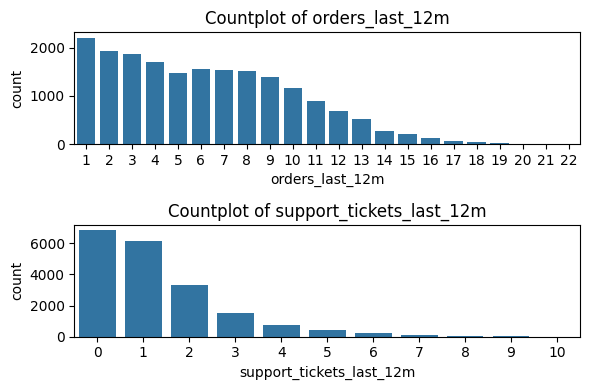

In [26]:
# Univariate Analysis : Check for the discrete numerical columns
no_of_rows = len(discrete_num_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(6, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(discrete_num_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Countplot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Business Insights:
1. Orders in last 12 months - The number of orders is right-skewed, with most customers placing fewer orders and progressively fewer customers showing very high purchase frequency. This shows majority of the people are purchasing less.
2. Support tickets in last 12 months - Support ticket counts are strongly right-skewed, with most customers raising zero or one ticket and only a small proportion generating multiple support requests. It shows majority of the people are satisfied with their purchases.

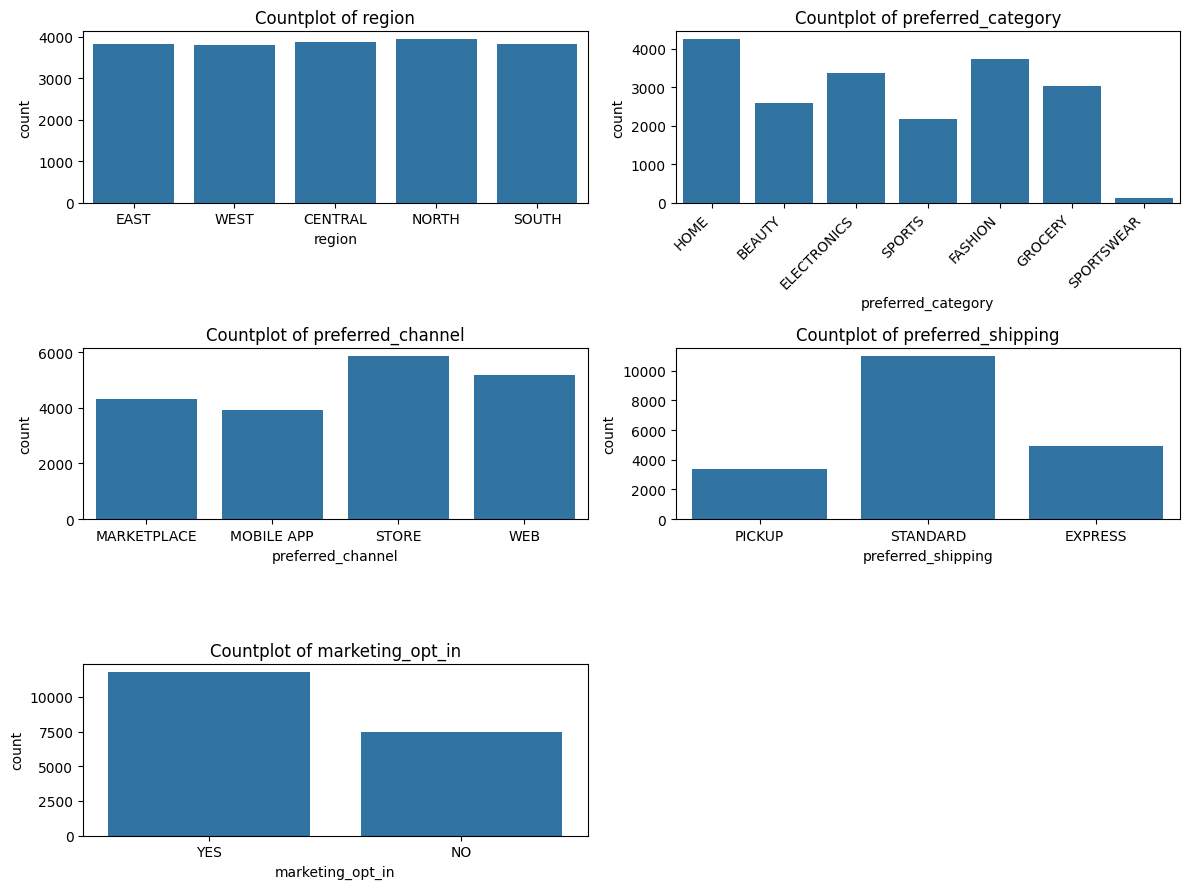

In [28]:
# Univariate Analysis : Check for the categorical columns
no_of_rows = (len(cat_cols)+1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(12, 3*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Countplot of {col}')
    if col=='preferred_category':
        plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Business Insights:
1. Region - Customers are almost evenly distributed across EAST, WEST, CENTRAL, NORTH, and SOUTH regions, indicating no major regional imbalance in the dataset.
2. Preferred Category - Customer preferences vary across product categories, with HOME and FASHION being more common, while SPORTS and BEAUTY have comparatively fewer customers.
3. Preferred Channel - STORE and WEB are the most preferred channels, while MOBILE APP and MARKETPLACE have relatively lower customer preferences. This is useful for distinguishing customers based on purchasing-channel preference.
4. Preferred Shipping - STANDARD shipping is clearly the dominant preference, followed by EXPRESS, while PICKUP is the least preferred option. Shipping preference can capture convenience and fulfillment behavior.
5. Marketing Optin - More customers have opted into marketing communications than opted out, although both groups have substantial representation. This can distinguish customers based on marketing engagement/preferences.

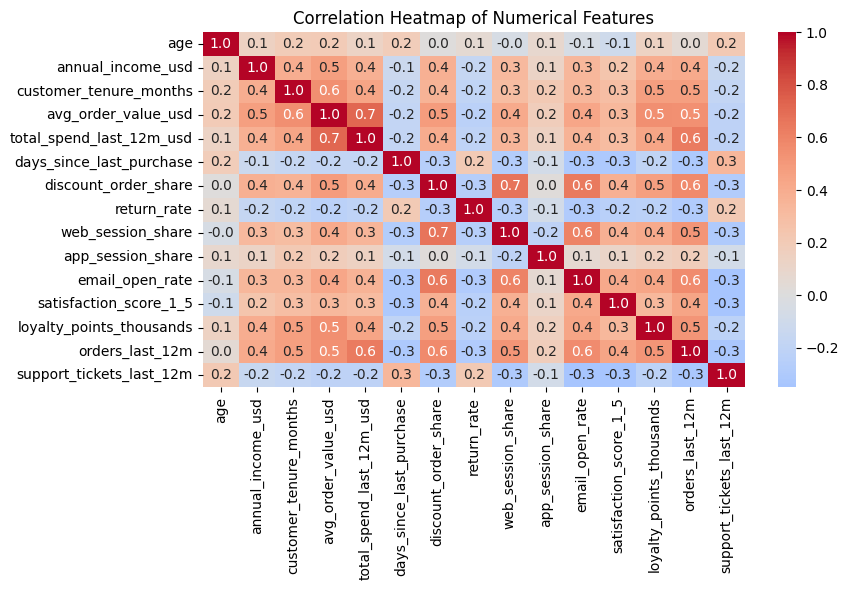

In [29]:
# Bivariate Analysis : Relation between all numerical columns by Heatmap
corr_matrix = df[num_cols+discrete_num_cols].corr()
plt.figure(figsize=(9,6))
sns.heatmap(corr_matrix, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

#### Business Insights:
The numerical features show mostly weak-to-moderate correlations, indicating that they capture different aspects of customer behavior. The strongest relationships are observed between average order value and total spend (0.7), and between discount order share and web session share (0.7), with no extremely high correlations suggesting severe redundancy.

The below are the important relationships:
1. Average Order Value vs Total Spend (r ≈ 0.7): Customers with higher average order values tend to have higher total annual spending, indicating a strong relationship between purchase value and overall customer value.
2. Discount Order Share vs Web Session Share (r ≈ 0.7): Customers with higher discount usage tend to have a higher share of web sessions, suggesting that discount-oriented customers may be more web-focused.
3. Total Spend vs Orders (r ≈ 0.6): Customers who place more orders generally contribute higher total spending, indicating that purchase frequency is an important driver of customer value.
4. Discount Order Share vs Orders (r ≈ 0.6): Higher discount usage is associated with greater order frequency, suggesting the presence of frequent but promotion-driven customers.
5. Web Session Share vs Email Open Rate (r ≈ 0.6): Higher web engagement is associated with stronger email engagement, indicating a broader pattern of digital customer engagement.
6. Email Open Rate vs Orders (r ≈ 0.6): Customers with higher email engagement tend to place more orders, suggesting a positive association between marketing engagement and purchasing activity.
7. Customer Tenure vs Average Order Value (r ≈ 0.6): Longer-tenured customers tend to have higher average order values, suggesting that established customers may make higher-value purchases.
8. Days Since Last Purchase vs Orders (r ≈ -0.3): Customers with higher purchase frequency tend to have purchased more recently, although the relationship is relatively weak

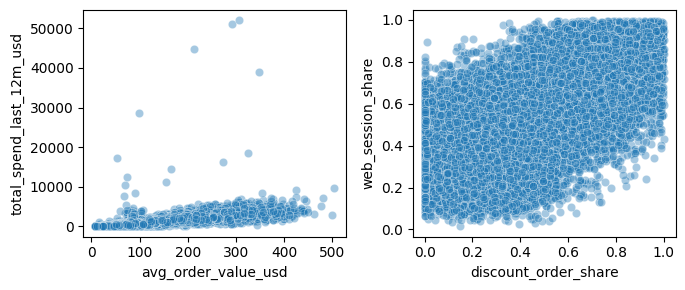

In [30]:
# Check the relation between two of the most strongest pairs
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
sns.scatterplot(data=df, x='avg_order_value_usd', y='total_spend_last_12m_usd', alpha=0.4, ax=axes[0])
sns.scatterplot(data=df, x='discount_order_share', y='web_session_share', alpha=0.4, ax=axes[1])
plt.tight_layout()
plt.show()

The features discount_order_share and web_session_share show a strong positive association (r ≈ 0.7), indicating potential overlap in the customer behavior captured by these features. In contrast, although avg_order_value_usd and total_spend_last_12m_usd are also positively correlated (r ≈ 0.7), the wide dispersion in total spending indicates that the two features capture distinct aspects of customer value and can be retained for clustering.

In [26]:
# Bivariate Analysis : Using Cramer's V, find the strength of association between every pairs
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.sum().sum()
    phi2 = chi2 / n
    r, k = table.shape
    
    # Bias correction
    phi2corr = max(0, phi2-((k-1)*(r-1))/(n-1))
    rcorr = r-((r-1)**2)/(n-1)
    kcorr = k-((k-1)**2)/(n-1)
    denominator = min(kcorr - 1, rcorr - 1)
    if denominator <= 0:
        return 0
    return np.sqrt(phi2corr / denominator)

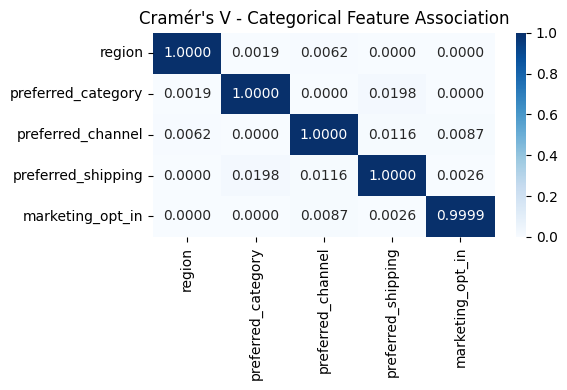

In [27]:
# Create and Plot the Cramer's Matrix
cramers_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for col1 in cat_cols:
    for col2 in cat_cols:
        cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

plt.figure(figsize=(6,4))
sns.heatmap(cramers_matrix, annot=True, fmt='.4f', cmap='Blues', vmin=0, vmax=1)
plt.title("Cramér's V - Categorical Feature Association")
plt.tight_layout()
plt.show()

Cramér’s V was used to evaluate the strength of association between categorical features and the values between the categorical features are found to be close to zero, indicating negligible associations among region, preferred_category, preferred_channel, preferred_shipping, and marketing_opt_in. Therefore, these features capture largely independent aspects of customer behavior and all are retained for clustering.

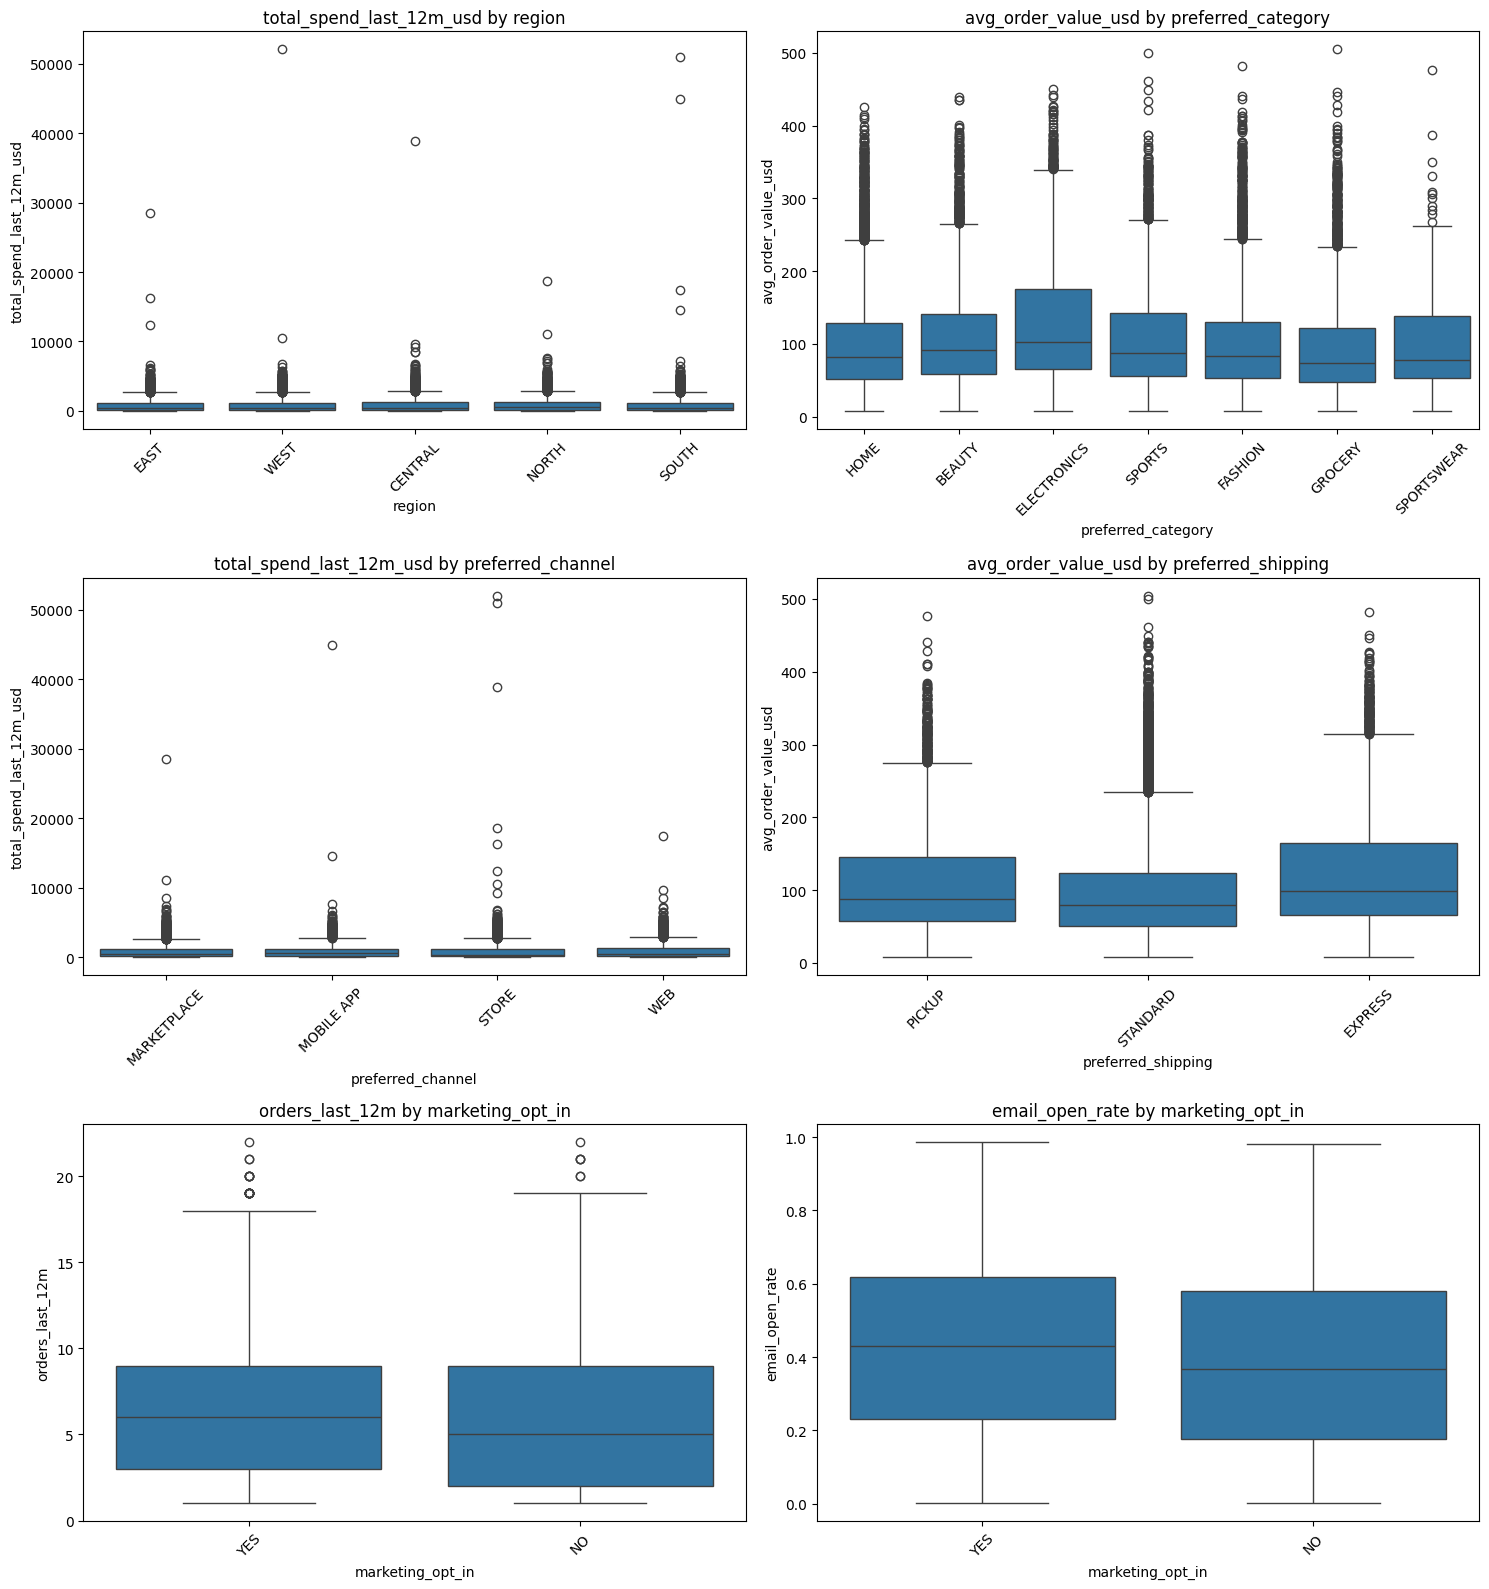

In [33]:
# Bivariate Analysis : Using boplot find the relation between numerical and categorical features
comparisons = [('region', 'total_spend_last_12m_usd'), ('preferred_category', 'avg_order_value_usd'),
               ('preferred_channel', 'total_spend_last_12m_usd'), ('preferred_shipping', 'avg_order_value_usd'),
               ('marketing_opt_in', 'orders_last_12m'), ('marketing_opt_in', 'email_open_rate')]
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes = axes.flatten()
for i, (cat, num) in enumerate(comparisons):
    sns.boxplot(data=df, x=cat, y=num, ax=axes[i])
    axes[i].set_title(f'{num} by {cat}')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Business Insights:
1. region vs total_spend_last_12m_usd - Total spending shows substantial overlap across all regions, with broadly similar central distributions. Region does not appear to strongly differentiate customers based on annual spending.
2. preferred_channel vs total_spend_last_12m_usd - Total spending distributions are broadly similar across MARKETPLACE, MOBILE APP, STORE, and WEB customers, with considerable overlap between groups. Extreme spend values are present across several channels.
3. preferred_shipping vs avg_order_value_usd - EXPRESS customers show a visibly higher median and broader distribution of average order value than STANDARD and PICKUP customers, suggesting that shipping preference is associated with differences in purchase value.
4. marketing_opt_in vs orders_last_12m - Customers who opted into marketing show a slightly higher median order frequency than customers who opted out, although the distributions overlap considerably.
5. marketing_opt_in vs email_open_rate - Marketing-opted-in customers show a moderately higher median email open rate, although substantial overlap exists between the two groups.
6. preferred_category vs avg_order_value_usd - Average order value varies across preferred product categories, with ELECTRONICS showing the highest median order value, while GROCERY and SPORTSWEAR appear comparatively lower.

In [28]:
# Outlier Analysis : Quantify the outliers using IQR
outlier_summary = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    mask = (df[col]<lower)|(df[col]>upper)
    outlier_summary.append({'feature': col, 'lower_bound': lower, 'upper_bound': upper, 
                            'outlier_count': mask.sum(), 'outlier_percentage': mask.mean() * 100})
outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary.round(2).sort_values('outlier_percentage', ascending=False)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
5,days_since_last_purchase,-35.10,74.50,2000,10.38
3,avg_order_value_usd,-69.45,261.72,1358,7.05
4,total_spend_last_12m_usd,-1435.71,2773.79,1250,6.49
7,return_rate,-0.10,0.23,1008,5.23
1,annual_income_usd,-28235.65,155638.92,997,5.18
2,customer_tenure_months,-39.05,98.95,989,5.13
11,satisfaction_score_1_5,1.50,6.26,169,0.88
9,app_session_share,-0.15,0.61,80,0.42
0,age,2.15,74.55,60,0.31
8,web_session_share,-0.19,1.29,0,0.00


In [29]:
# Describe the features with most outliers
outlier_cols = ['days_since_last_purchase', 'avg_order_value_usd', 'total_spend_last_12m_usd', 'return_rate', 
                'annual_income_usd', 'customer_tenure_months']
df[outlier_cols].describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
days_since_last_purchase,19264.0,33.878120,61.803473,0.0000,0.2000,6.0000,14.550,33.4000,136.9850,318.5220,1200.000
avg_order_value_usd,19264.0,110.290112,78.958564,8.0000,13.2700,54.7375,84.975,137.5300,281.2285,355.3488,504.590
total_spend_last_12m_usd,19264.0,875.095781,1256.775342,0.1279,23.6423,142.8550,463.295,1195.2300,3045.9485,4505.3918,52054.000
return_rate,19264.0,0.080625,0.075496,0.0000,0.0020,0.0270,0.058,0.1090,0.2360,0.3510,0.744
annual_income_usd,19264.0,70291.084284,43694.968264,0.0000,16007.1912,40717.3100,59528.065,86685.9525,156777.8905,232530.3741,300000.000
customer_tenure_months,19264.0,34.925395,31.061762,0.1000,1.2000,12.7000,25.600,47.2000,99.9000,146.6000,180.000


Outlier analysis identified several extreme observations; however, validation confirmed that these values are legitimate and represent genuine customer behavior. Therefore, no records are removed. Highly right-skewed features will be log-transformed to reduce the influence of extreme values on distance-based clustering, while the remaining features will be retained in their original form.

Log transformation required for: days_since_last_purchase, avg_order_value_usd, total_spend_last_12m_usd, annual_income_usd

### Transformation of the features

In [30]:
# Apply log transformation on the required columns
log_cols = ['days_since_last_purchase', 'avg_order_value_usd', 'total_spend_last_12m_usd', 'annual_income_usd']
for col in log_cols:
    df[col+'_log'] = np.log1p(df[col])

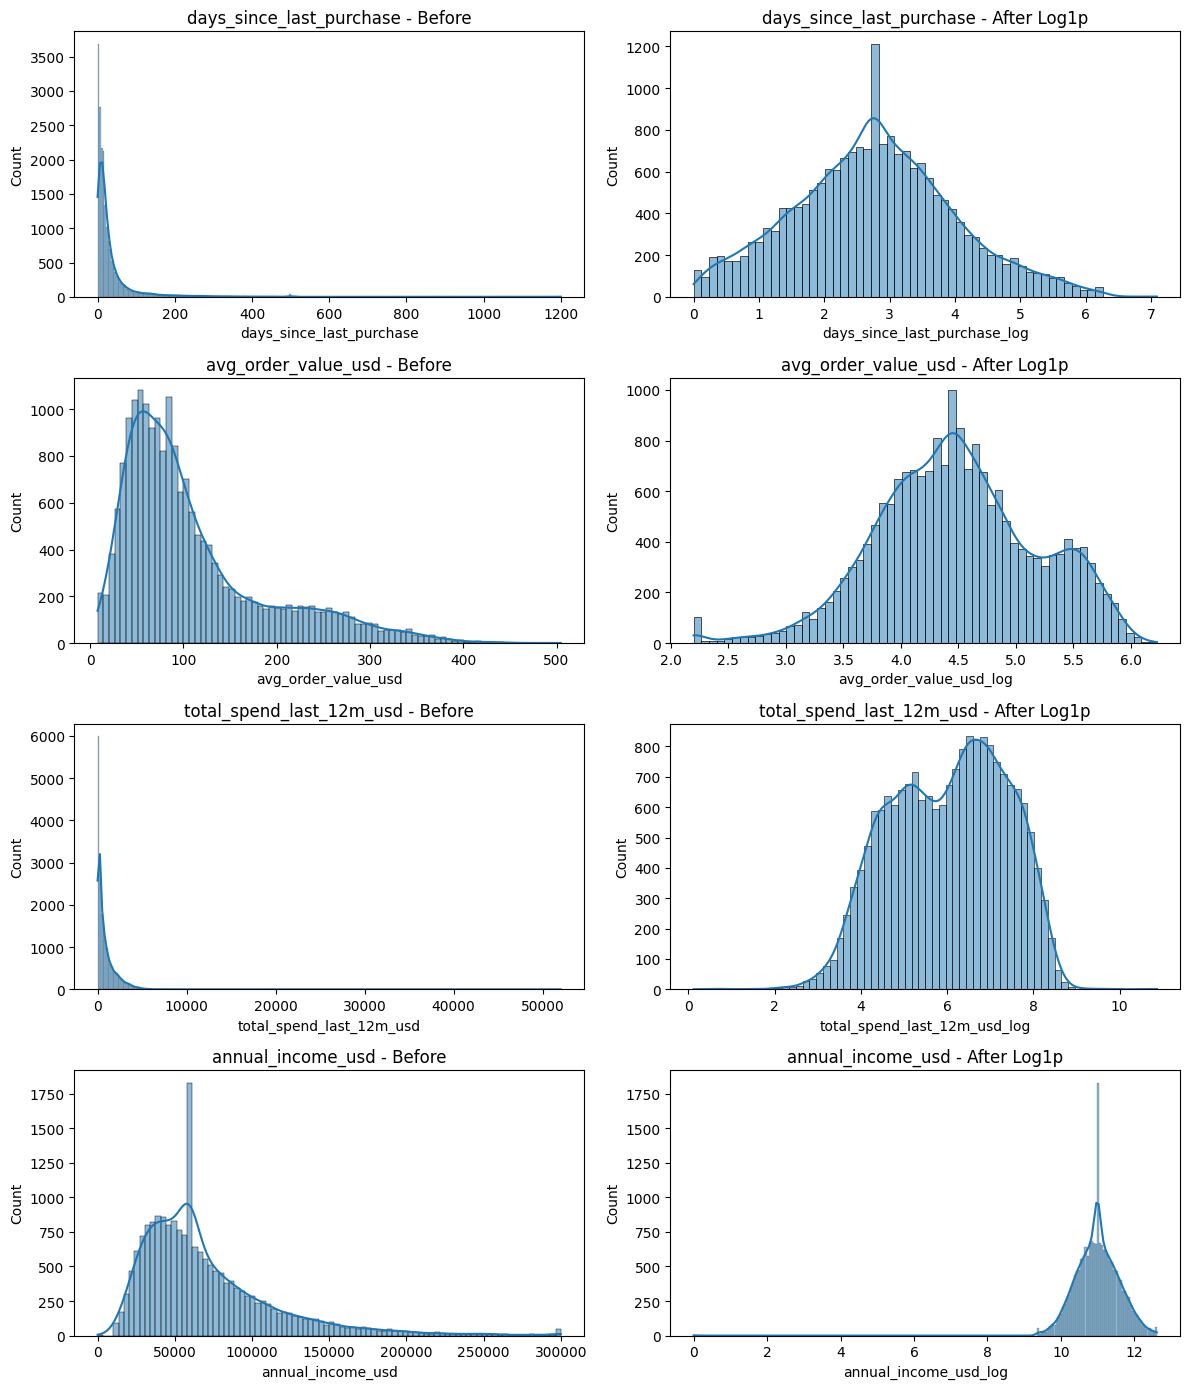

In [31]:
# Plot the distribution before and after log tranformation
fig, axes = plt.subplots(len(log_cols), 2, figsize=(12, 14))
for i, col in enumerate(log_cols):
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} - Before')
    sns.histplot(df[col+'_log'], kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} - After Log1p')
plt.tight_layout()
plt.show()

Log1p transformation has been applied to the above features and it has substantially reduced the right skewness and influence of extreme observations in total_spend_last_12m_usd, annual_income_usd, days_since_last_purchase, and avg_order_value_usd. The transformed features provide more balanced distributions and will therefore be used for clustering instead of their original versions.

### Data Preprocessing

In [32]:
# Finalize the clustering features
log_features = ['days_since_last_purchase_log', 'avg_order_value_usd_log', 'total_spend_last_12m_usd_log', 
                'annual_income_usd_log']
num_features = [x for x in num_cols if x not in log_cols]
X = df[log_features+num_features+cat_cols+discrete_num_cols]
X.head()

,days_since_last_purchase_log,avg_order_value_usd_log,total_spend_last_12m_usd_log,annual_income_usd_log,age,customer_tenure_months,discount_order_share,return_rate,web_session_share,app_session_share,email_open_rate,satisfaction_score_1_5,loyalty_points_thousands,region,preferred_category,preferred_channel,preferred_shipping,marketing_opt_in,orders_last_12m,support_tickets_last_12m
0,3.484312,3.714547,3.571221,10.994220,48.9,5.3,0.458,0.085,0.297,0.167,0.391,3.81,2.28,EAST,HOME,MARKETPLACE,PICKUP,YES,1,1
1,0.262364,4.870607,6.752691,11.357236,51.2,23.4,0.661,0.093,0.782,0.218,0.715,3.91,5.03,EAST,BEAUTY,MARKETPLACE,PICKUP,YES,8,2
2,3.770459,5.397574,8.097566,11.584134,36.7,77.5,0.829,0.060,0.591,0.409,0.623,4.41,10.00,WEST,ELECTRONICS,MOBILE APP,STANDARD,NO,14,1
3,3.668677,4.521136,6.561879,10.337081,44.9,28.6,0.431,0.037,0.372,0.628,0.558,4.44,5.79,CENTRAL,ELECTRONICS,STORE,STANDARD,NO,8,1
4,3.321432,4.214347,3.976874,10.967955,48.5,5.5,0.075,0.276,0.285,0.403,0.160,3.87,1.49,NORTH,ELECTRONICS,WEB,EXPRESS,NO,1,2


### Model Training

In [48]:
# Create a preprocessor to scale and encode the required features
scale_cols = num_features + log_features + discrete_num_cols
preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), scale_cols), 
                                               ('cat', OneHotEncoder(handle_unknown='ignore', 
                                                                     sparse_output=False), cat_cols)],
                                 remainder='drop')
X_preprocessed = preprocessor.fit_transform(X)

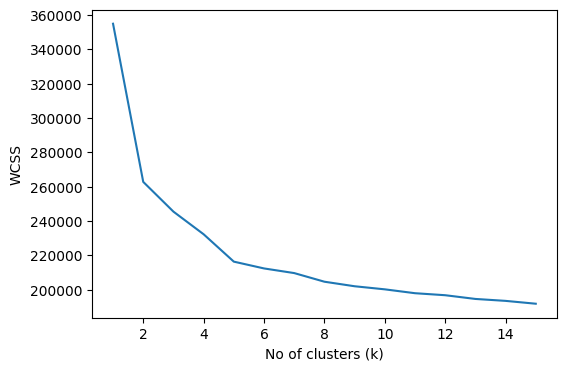

In [49]:
# Use elbow method to find the k value
wcss = []
for k in range(1, 16):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_preprocessed)
    wcss.append(model.inertia_)
# Plot the Elbow graph
plt.figure(figsize=(6,4))
plt.plot(range(1,16), wcss)
plt.xlabel('No of clusters (k)')
plt.ylabel('WCSS')
plt.show()

From the Elbow graph, the best value of k seems to be 5 as the variation becomes negligible after this point.

In [52]:
# Train the model with KMeans Clustering Algorithm
kmeans_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                  ('kmeans', KMeans(n_clusters=5, random_state=42, n_init=10))])
clusters = kmeans_pipeline.fit_predict(X)

K-Means Silhouette Score: 0.117


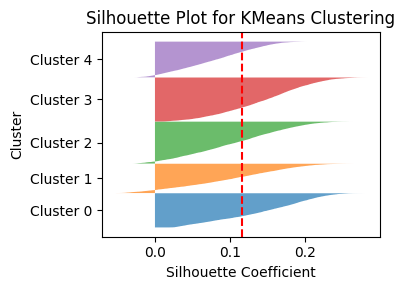

In [63]:
# Silhouette Plot for KMeans Clustering
silhouette_values = silhouette_samples(X_preprocessed, clusters)
avg_silhouette = silhouette_score(X_preprocessed, clusters)
print(f'K-Means Silhouette Score: {avg_silhouette:.3f}')
plt.figure(figsize=(4,3))
y_lower = 10
cluster_centers = []
cluster_names = []
for cluster in range(5):
    values = silhouette_values[clusters == cluster]
    values.sort()
    size = len(values)
    y_upper = y_lower+size
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, values, alpha=0.7)
    cluster_centers.append((y_lower+y_upper) / 2)
    cluster_names.append(f'Cluster {cluster}')
    y_lower = y_upper + 20
plt.axvline(avg_silhouette, color='red', linestyle='--', label=f'Average = {avg_silhouette:.3f}')
plt.yticks(cluster_centers, cluster_names)
plt.xlabel('Silhouette Coefficient')
plt.ylabel('Cluster')
plt.title('Silhouette Plot for KMeans Clustering')
plt.tight_layout()
plt.show()

In [55]:
# Check the Cluster Stability for KMeans Clustering Algorithm
base_model = KMeans(n_clusters=5, random_state=42, n_init=10)
base_labels = base_model.fit_predict(X_preprocessed)
for seed in [10, 20, 30, 40, 50]:
    model = KMeans(n_clusters=5, random_state=seed, n_init=10)
    labels = model.fit_predict(X_preprocessed)
    ari = adjusted_rand_score(base_labels, labels)
    print(f'Seed {seed}: ARI = {ari:.3f}')

Seed 10: ARI = 0.999
Seed 20: ARI = 0.999
Seed 30: ARI = 0.999
Seed 40: ARI = 0.999
Seed 50: ARI = 0.998


The K=5 solution achieved a Silhouette Score of 0.117, indicating that the clusters have considerable overlap and are not strongly separated geometrically. However, the clustering demonstrated excellent stability, with an Adjusted Rand Index (ARI) of almost 1 across all tested random seeds, showing highly consistent cluster assignments.

Despite the relatively low Silhouette Score, the cluster profiles show meaningful and interpretable differences in customer value, purchase frequency, recency, loyalty, digital engagement, discount behavior, satisfaction, and support activity. Therefore, the K=5 solution is retained as a stable and business-interpretable customer segmentation, while acknowledging the moderate overlap between clusters.

### Model Training : KMeans with PCA

In [59]:
# PCA to remove noise and redundancy
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_preprocessed)
print("Components:", pca.n_components_)
print("Variance retained:", pca.explained_variance_ratio_.sum())

Components: 20
Variance retained: 0.9099898101788533


PCA reduced the feature space while retaining approximately 91% of the original variance. It may have reduced some redundancy and improved the clustering structure, but the improvement should be validated rather than automatically attributed to noise removal.

In [61]:
# Train the model with KMeans Clustering with PCA
pca_kmeans_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('pca', pca), 
                                      ('kmeans', KMeans(n_clusters=5, random_state=42, n_init=10))])
clusters_pca = pca_kmeans_pipeline.fit_predict(X)

K-Means Silhouette Score: 0.134


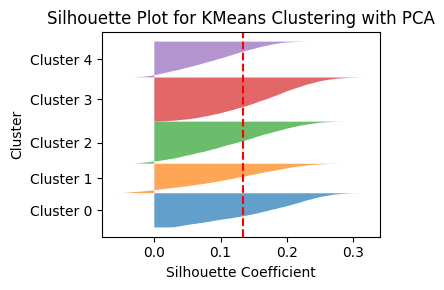

In [64]:
# Silhouette Plot for KMeans Clustering with PCA
silhouette_values = silhouette_samples(X_pca, clusters)
avg_silhouette = silhouette_score(X_pca, clusters)
print(f'K-Means Silhouette Score: {avg_silhouette:.3f}')
plt.figure(figsize=(4,3))
y_lower = 10
cluster_centers = []
cluster_names = []
for cluster in range(5):
    values = silhouette_values[clusters == cluster]
    values.sort()
    size = len(values)
    y_upper = y_lower+size
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, values, alpha=0.7)
    cluster_centers.append((y_lower+y_upper) / 2)
    cluster_names.append(f'Cluster {cluster}')
    y_lower = y_upper + 20
plt.axvline(avg_silhouette, color='red', linestyle='--', label=f'Average = {avg_silhouette:.3f}')
plt.yticks(cluster_centers, cluster_names)
plt.xlabel('Silhouette Coefficient')
plt.ylabel('Cluster')
plt.title('Silhouette Plot for KMeans Clustering with PCA')
plt.tight_layout()
plt.show()

In [46]:
# Model Stability for KMeans Clustering with PCA
base_model = KMeans(n_clusters=5, random_state=42, n_init=10)
base_labels = base_model.fit_predict(X_pca)
for seed in [10, 20, 30, 40, 50]:
    model = KMeans(n_clusters=5, random_state=seed, n_init=10)
    labels = model.fit_predict(X_pca)
    ari = adjusted_rand_score(base_labels, labels)
    print(f"Seed {seed}: ARI = {ari:.3f}")

Seed 10: ARI = 0.999
Seed 20: ARI = 1.000
Seed 30: ARI = 0.999
Seed 40: ARI = 0.999
Seed 50: ARI = 0.998


PCA retained approximately 91% of the total variance using 20 principal components and improved the K=5 Silhouette Score from 0.117 to 0.134. The PCA-based clustering also demonstrated excellent stability, achieving an ARI of almost 1 across all tested random seeds. The final model will therefore be assessed based on whether the five PCA-derived clusters also produce distinct and business-interpretable customer profiles.

In [68]:
# Check the cluster sizes
df_pca_clustered = df.loc[X.index].copy()
df_pca_clustered['cluster'] = pd.Series(labels_pca, index=X.index)
cluster_counts = (df_pca_clustered['cluster'].value_counts().sort_index())
cluster_sizes = pd.DataFrame({'Count': cluster_counts, 
                              'Percentage': (cluster_counts/len(df_pca_clustered)*100).round(2)})
cluster_sizes

,Count,Percentage
cluster,,
0,4581,23.78
1,3568,18.52
2,3704,19.23
3,3053,15.85
4,4358,22.62


In [69]:
# Check the Cluster Summary for KMeans with PCA
profile_cols = num_cols+discrete_num_cols
cluster_profile = df_pca_clustered.groupby('cluster')[profile_cols].median().round(2).T
cluster_profile

cluster,0,1,2,3,4
age,28.40,32.80,38.50,50.50,43.80
annual_income_usd,37405.19,67033.70,59528.06,50480.35,100320.38
customer_tenure_months,10.20,25.60,30.70,17.20,68.45
avg_order_value_usd,45.55,110.19,85.01,70.84,222.62
total_spend_last_12m_usd,112.72,819.88,536.03,117.62,2111.19
days_since_last_purchase,18.40,10.75,12.40,77.90,8.95
discount_order_share,0.21,0.80,0.41,0.25,0.65
return_rate,0.08,0.05,0.05,0.12,0.04
web_session_share,0.37,0.86,0.50,0.33,0.68
app_session_share,0.18,0.14,0.32,0.18,0.28


In [71]:
# Assign the PCA Cluster labels into the Dataframe
pca_clusters = pd.Series(labels_pca, index=X.index, name='cluster')
df['pca_cluster'] = pca_clusters

### Gaussian Mixture Model

In [72]:
# Train GMM and check the Silhouette Score
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42, n_init=10)
labels_gmm = gmm.fit_predict(X_pca)
gmm_silhouette = silhouette_score(X_pca, labels_gmm)
print(f"GMM Silhouette Score: {gmm_silhouette:.3f}")

GMM Silhouette Score: -0.021


Gaussian Mixture Modeling (GMM) was evaluated as an alternative to K-Means using the same PCA-transformed dataset. However, this algorithm achieved a negative silhouette score, indicating comparable cluster separation. Since PCA + K-Means also demonstrated excellent stability (ARI = 1.000) and produced clearly interpretable customer segments, K-Means is retained as the final clustering algorithm.

### Model Conclusion

Customer segmentation was performed using K-Means clustering after comprehensive data cleaning, exploratory analysis, feature transformation, encoding, and scaling. Extreme observations were validated as legitimate customer behavior rather than data errors; therefore, these records were retained. Highly right-skewed features including annual income, average order value, total annual spend, and days since last purchase were transformed using log1p to reduce skewness and the influence of extreme values.

The baseline K-Means model with five clusters achieved a Silhouette Score of approximately 0.117. PCA was subsequently applied to reduce noise and redundancy, retaining 90.81% of the total variance using 20 principal components. K-Means trained on the PCA-transformed data improved the Silhouette Score to approximately 0.134, indicating improved cluster separation, although some overlap between customer segments remains.

The PCA-based K-Means model also demonstrated excellent stability, achieving an Adjusted Rand Index (ARI) of 1.000 across all tested random seeds. The resulting clusters remained clearly interpretable in terms of customer value, purchasing behavior, recency, loyalty, digital engagement, satisfaction, and support activity.

Gaussian Mixture Modeling was evaluated as an alternative clustering approach but achieved negative Silhouette Score. Therefore, PCA + K-Means with five clusters was selected as the final model because it combines improved separation, excellent stability, and clear business interpretability.

### Final Customer Segments

#### Cluster 0 : Low-Value Emerging 
Customers are relatively young and new, with low income, spending, order value, loyalty, purchase frequency, and digital engagement.
#### Cluster 1 : Discount-Driven & Digital
Customers are highly active and digitally engaged, with very high discount usage, web activity, email engagement, and frequent purchasing.
#### Cluster 2 : Mainstream Active
Customers show balanced purchasing and engagement behavior, with moderate income, spending, loyalty, and regular purchase activity.
#### Cluster 3 : At-Risk / Disengaged
Customers show prolonged purchase inactivity, low spending and engagement, the lowest satisfaction, higher return rates, and the highest support-ticket activity.
#### Cluster 4 : High-Value Loyal
Customers represent the strongest-value segment, with the highest income, tenure, order value, total spending, purchase frequency, loyalty, and satisfaction.

### Results

In [74]:
# Display the dataframe with cluster labels
cluster_mapping = {0: 'Low-Value Emerging', 1: 'Discount-Driven & Digital', 2: 'Mainstream Active', 
                   3: 'At-Risk / Disengaged', 4: 'High-Value Loyal'}
df.rename(columns={'pca_cluster': 'customer_segment'}, inplace=True)
df['customer_segment'] = df['customer_segment'].replace(cluster_mapping)
df.head()

,customer_id,age,annual_income_usd,region,customer_tenure_months,orders_last_12m,avg_order_value_usd,total_spend_last_12m_usd,days_since_last_purchase,discount_order_share,...,loyalty_points_thousands,preferred_category,preferred_channel,preferred_shipping,marketing_opt_in,days_since_last_purchase_log,avg_order_value_usd_log,total_spend_last_12m_usd_log,annual_income_usd_log,customer_segment
0,C113906,48.9,59528.065,EAST,5.3,1,40.04,34.56,31.6,0.458,...,2.28,HOME,MARKETPLACE,PICKUP,YES,3.484312,3.714547,3.571221,10.994220,Low-Value Emerging
1,C105664,51.2,85581.530,EAST,23.4,8,129.40,855.36,0.3,0.661,...,5.03,BEAUTY,MARKETPLACE,PICKUP,YES,0.262364,4.870607,6.752691,11.357236,Discount-Driven & Digital
2,C105107,36.7,107379.490,WEST,77.5,14,219.87,3285.46,42.4,0.829,...,10.00,ELECTRONICS,MOBILE APP,STANDARD,NO,3.770459,5.397574,8.097566,11.584134,High-Value Loyal
3,C117240,44.9,30854.820,CENTRAL,28.6,8,90.94,706.60,38.2,0.431,...,5.79,ELECTRONICS,STORE,STANDARD,NO,3.668677,4.521136,6.561879,10.337081,Mainstream Active
4,C113089,48.5,57984.880,NORTH,5.5,1,66.65,52.35,26.7,0.075,...,1.49,ELECTRONICS,WEB,EXPRESS,NO,3.321432,4.214347,3.976874,10.967955,At-Risk / Disengaged


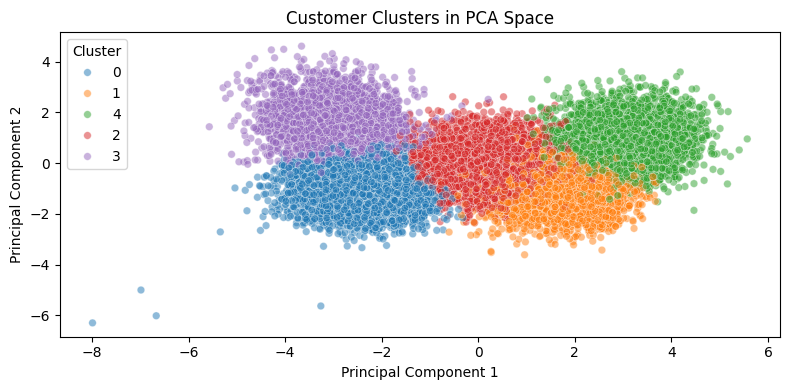

In [76]:
# Visualize the clusters in PCA space
pca_plot = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'Cluster': labels_pca.astype(str)})
plt.figure(figsize=(8, 4))
sns.scatterplot(data=pca_plot, x='PC1', y='PC2', hue='Cluster', palette='tab10', alpha=0.5, s=30)
plt.title('Customer Clusters in PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

### Model Deployment

In [82]:
# Save the model as a pickle file
category_values = {col: sorted(df[col].dropna().astype(str).unique().tolist()) for col in cat_cols}
raw_log_mapping = {'days_since_last_purchase': 'days_since_last_purchase_log', 
                   'avg_order_value_usd': 'avg_order_value_usd_log', 
                   'total_spend_last_12m_usd': 'total_spend_last_12m_usd_log', 
                   'annual_income_usd': 'annual_income_usd_log'}
raw_numeric_cols = num_features + discrete_num_cols + list(raw_log_mapping.keys())
numeric_defaults = {col: float(df[col].median()) for col in raw_numeric_cols}
model_bundle = {'pipeline': pca_kmeans_pipeline, 'cluster_mapping': cluster_mapping, 'num_features': num_features,
                'log_features': log_features, 'cat_cols': cat_cols, 'discrete_num_cols': discrete_num_cols, 
                'raw_log_mapping': raw_log_mapping, 'category_values': category_values, 
                'numeric_defaults': numeric_defaults, 'model_feature_columns': X.columns.tolist()}
joblib.dump(model_bundle, 'customer_segmentation_model.pkl')

['customer_segmentation_model.pkl']